# Clustering với k-Means

In [1]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plt

np.set_printoptions(precision=3, suppress=True)

## 1. Dữ liệu giả định

**Giả sử có 3 tập**
1. Set 1: 50 điểm
1. Set 2: 75 điểm
1. Set 3: 100 điểm

In [2]:
np.random.seed(1)
x1,y1 = np.random.normal(loc=2,scale=1,size=50), np.random.normal(loc=5,scale=1,size=50)
x2,y2 = np.random.normal(loc=5,scale=1,size=75), np.random.normal(loc=1,scale=1,size=75)
x3,y3 = np.random.normal(loc=8,scale=1,size=100), np.random.normal(loc=7,scale=1,size=100)

**=== Hiển thị 3 tập để kiểm tra ===**

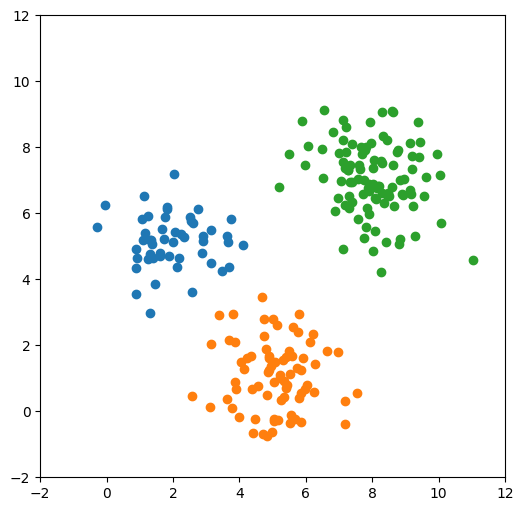

In [3]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(x1, y1)
plt.scatter(x2, y2)
plt.scatter(x3, y3)
plt.show()

### Ghép nối dữ liệu lại thành 1 tập chưa được clustered

In [4]:
# Ghép 3 tập thành một tập dữ liệu
X = np.concatenate([
    np.column_stack((x1, y1)),
    np.column_stack((x2, y2)),
    np.column_stack((x3, y3))
])

import pandas as pd

df = pd.DataFrame(X, columns=['x', 'y'])


In [5]:
df.head(5)

,x,y
0,3.624345,5.300170
1,1.388244,4.647750
2,1.471828,3.857482
3,0.927031,4.650657
4,2.865408,4.791106


In [6]:
df.shape

(225, 2)

In [7]:
dat1 = np.stack([x1, y1]).T
dat2 = np.stack([x2,y2]).T
dat3 = np.stack([x3,y3]).T

**=== Tập dữ liệu giả định có 225 dòng, 2 cột (x,y) ===**

In [9]:
dat = np.concatenate([dat1, dat2, dat3], axis=0)

print(dat.shape)


(225, 2)


### Sắp ngẫu nhiên các dòng

In [10]:
np.random.seed(2)
# Xáo trộn ngẫu nhiên các dòng
np.random.seed(2)
np.random.shuffle(dat)

print(dat.shape)
print(dat[:5])

(225, 2)
[[ 5.963  7.467]
 [ 8.956  7.053]
 [ 0.899  3.556]
 [ 4.703 -0.674]
 [ 4.961  1.369]]


### Kiểm tra lại với biểu đồ scatter

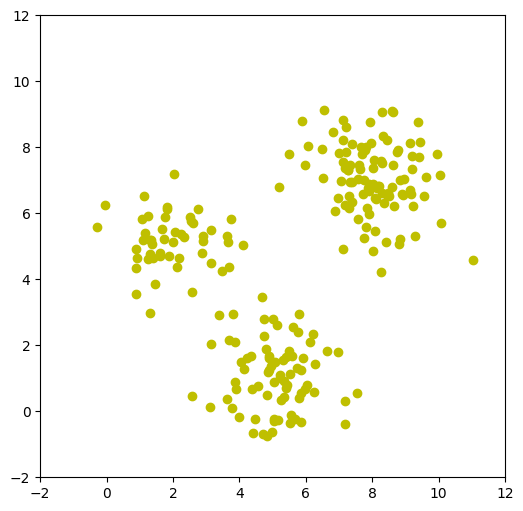

In [11]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(dat[:,0], dat[:,1], color='y')
plt.show()

## 2. Thực hiện phân cụm

### 2.1. Giả sử K=3 và tìm 3 điểm ban đầu ngẫu nhiên

In [12]:
K = 3

In [13]:
# Chọn ngẫu nhiên 3 điểm ban đầu
np.random.seed(30)

random_indices = np.random.choice(len(dat), size=K, replace=False)
centroids = dat[random_indices]

print("3 điểm ban đầu:")
print(centroids)

3 điểm ban đầu:
[[5.338 0.438]
 [2.617 5.698]
 [4.9   1.243]]


**Gán các trung tâm cho 3 điểm này**

In [14]:
K = 3

# Chọn 3 điểm ban đầu ngẫu nhiên
np.random.seed(30)
idx = np.random.choice(len(dat), K, replace=False)

# Gán 3 điểm này làm 3 trung tâm ban đầu
centers = dat[idx]

print("Chỉ số của 3 điểm được chọn:", idx)
print("3 trung tâm ban đầu:")
print(centers)


Chỉ số của 3 điểm được chọn: [  8 180 170]
3 trung tâm ban đầu:
[[5.338 0.438]
 [2.617 5.698]
 [4.9   1.243]]


**=== Vẽ K điểm centroids ban đầu lên biểu đồ ===**

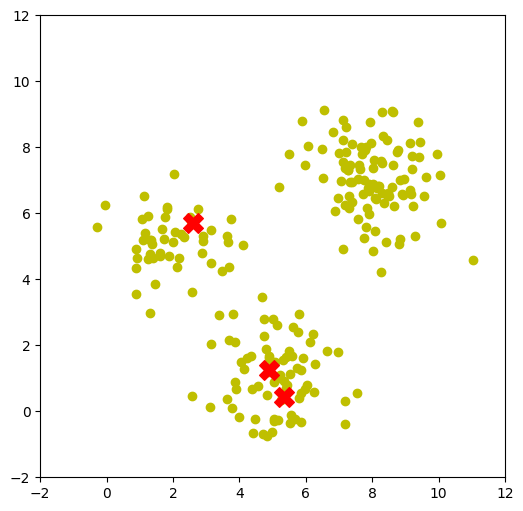

In [15]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])
# Vẽ toàn bộ dữ liệu
plt.scatter(dat[:,0], dat[:,1], color='y')
# Vẽ K centroids ban đầu
plt.scatter(centroids[:,0], centroids[:,1],
            color='r', marker='X', s=200)

plt.show()

### 2.2. Tiến hành gom cụm lần 1

**=== Khởi tạo K danh sách rỗng (để chứa các điểm của mỗi cluster) ===**

In [16]:
cList = [[] for i in range(K)]
print(cList)

[[], [], []]


**=== Với mỗi sample, tìm xem nó gần điểm centroid nào nhất ===**

In [17]:
for sample in dat:
    # Tính khoảng cách từ sample đến K centroid
    distances = []

    for centroid in centroids:
        distance = np.linalg.norm(sample - centroid)
        distances.append(distance)

    # Tìm centroid gần sample nhất
    cluster = np.argmin(distances)

    # Đưa sample vào cluster tương ứng
    cList[cluster].append(sample)
    

In [19]:
# Thử kiểm tra lại mỗi list
for i in range(K): 
    print(len(cList[i]))

29
138
58


**=== Thử lấy cluster đầu tiên ra và đánh giá ===**

In [20]:
np.stack(cList[0]).shape

(29, 2)

In [21]:
# Tọa độ của điểm centroid mới
new_centroid = np.mean(np.stack(cList[0]), axis=0)
print(new_centroid)

[5.584 0.19 ]


**=== Tính lại các điểm centroids ===**

In [22]:
centroids = np.array([
    np.mean(np.stack(cList[i]), axis=0)
    for i in range(K)
])

print(centroids)

[[5.584 0.19 ]
 [5.764 6.535]
 [5.594 2.377]]


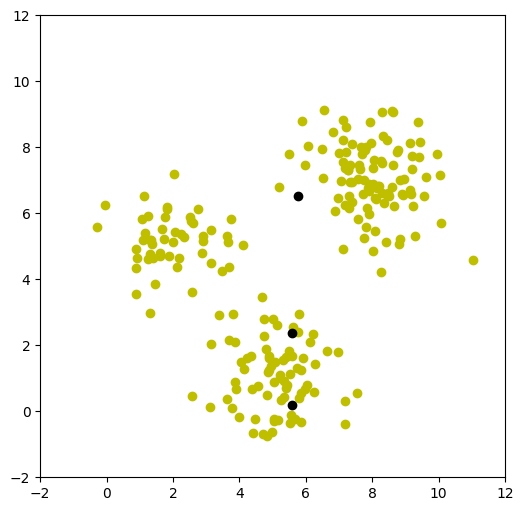

In [23]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(dat[:,0], dat[:,1], color='y')
plt.scatter(centroids[:,0], centroids[:,1], color='k')

plt.show()

### 2.3. Tiến hành gom cụm lần 2

**=== Tiếp tục khởi tạo K list rỗng để chứa các cluster mới ===**

In [24]:
cList = [[] for _ in range(K)]
for sample in dat:
    kq = np.sum((sample - centroids)**2, axis=1)
    min_d_idx = np.argmin(kq)
    cList[min_d_idx].append(sample)

# Tính giá trị của các centroids mới
centroids = [np.stack(cList[i]).mean(axis=0) for i in range(K)]
centroids = np.stack(centroids)
print(centroids)

[[5.099 0.36 ]
 [6.268 6.612]
 [4.451 2.574]]


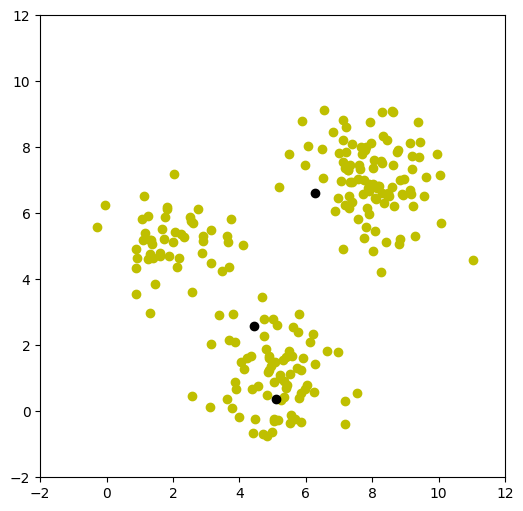

In [25]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(dat[:,0], dat[:,1], color='y')
plt.scatter(centroids[:,0], centroids[:,1], color='k')

plt.show()

### 2.4. Tiến hành gom cụm lần 3

**=== Tiếp tục khởi tạo K list rỗng để chứa các cluster mới ===**

In [26]:
cList = [[] for _ in range(K)]
for sample in dat:
    kq = np.sum((sample - centroids)**2, axis=1)
    min_d_idx = np.argmin(kq)
    cList[min_d_idx].append(sample)

centroids = [np.stack(cList[i]).mean(axis=0) for i in range(K)]
centroids = np.stack(centroids)
print(centroids)

[[5.225 0.569]
 [7.744 7.031]
 [2.898 4.079]]


**==> Nhận xét: các giá trị trung tâm gần như ít thay đổi**

In [29]:
# Lấy ra các cluster
for i in range(K):
    print(f"Cluster {i}:")
    print(np.array(cList[i]))
    print("-" * 50)

Cluster 0:
[[ 4.703 -0.674]
 [ 4.961  1.369]
 [ 5.338  0.438]
 [ 5.594  1.68 ]
 [ 5.047 -0.237]
 [ 4.376  0.674]
 [ 3.104  0.139]
 [ 3.878  0.88 ]
 [ 3.905  0.68 ]
 [ 5.683 -0.22 ]
 [ 5.351  0.927]
 [ 4.003 -0.182]
 [ 4.864  1.202]
 [ 4.825  0.502]
 [ 7.191 -0.397]
 [ 5.249  0.334]
 [ 2.565  0.454]
 [ 5.232  1.109]
 [ 5.529  1.129]
 [ 7.528  0.557]
 [ 5.863 -0.332]
 [ 3.77   0.109]
 [ 5.869  0.565]
 [ 5.846  1.241]
 [ 5.033  0.89 ]
 [ 5.169 -0.273]
 [ 5.315  1.563]
 [ 4.396 -0.651]
 [ 5.741  1.314]
 [ 5.521 -0.343]
 [ 4.975 -0.627]
 [ 3.627  0.383]
 [ 6.628  1.824]
 [ 5.078  1.503]
 [ 5.551 -0.119]
 [ 4.483 -0.233]
 [ 4.9    1.243]
 [ 6.967  1.811]
 [ 5.214  0.998]
 [ 4.553  0.774]
 [ 5.403  0.713]
 [ 4.819 -0.761]
 [ 5.901  1.619]
 [ 5.802  0.413]
 [ 7.187  0.3  ]
 [ 6.039  0.801]
 [ 5.986  0.689]
 [ 5.044 -0.306]
 [ 4.14   1.281]
 [ 5.441  0.797]
 [ 6.236  0.599]
 [ 6.274  1.42 ]]
--------------------------------------------------
Cluster 1:
[[ 5.963  7.467]
 [ 8.956  7.053]
 [ 7.893

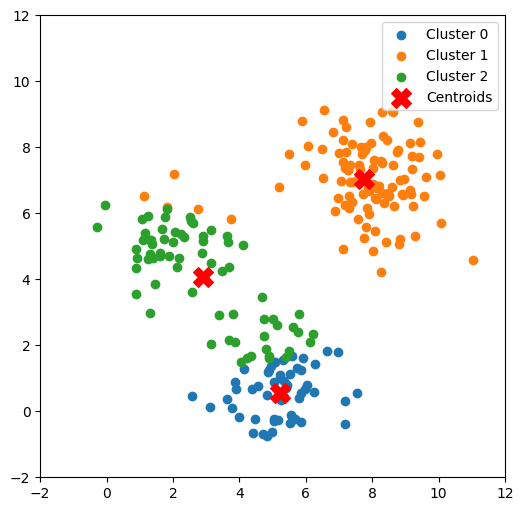

In [30]:
# Hiển thị 3 cluster lên biểu đồ
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

for i in range(K):
    cluster = np.array(cList[i])
    plt.scatter(cluster[:, 0], cluster[:, 1], label=f'Cluster {i}')

# Hiển thị tâm các cluster
plt.scatter(centroids[:, 0], centroids[:, 1],
            marker='X', s=200, color='red', label='Centroids')

plt.legend()
plt.show()